In [ ]:
import os
import urllib.request

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import transformers
from dotenv import load_dotenv
from google import genai
from PIL import Image
from transformers import (
    Blip2ForConditionalGeneration,
    Blip2Processor,
    CLIPModel,
    CLIPProcessor,
)

In [2]:
model_id = "openai/clip-vit-base-patch32"
clip_pipeline = transformers.pipeline(
    task="zero-shot-image-classification",
    model=model_id,
    device_map="auto",
    dtype="auto",
)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [3]:
candidate_labels = ["cricket", "ladybug", "spider"]
image_url = "https://homl.info/ladybug"

results = clip_pipeline(
    image_url,
    candidate_labels=candidate_labels,
    hypothesis_template="This is a photo of a {}.",
)
results

[{'score': 0.997286319732666, 'label': 'ladybug'},
 {'score': 0.0016505635576322675, 'label': 'spider'},
 {'score': 0.0010631218319758773, 'label': 'cricket'}]

In [4]:
candidate_labels2 = ["dandelion", "lily", "popy", "rose", "sunflower"]
results2 = clip_pipeline(
    image_url,
    candidate_labels=candidate_labels2,
    hyphjotesis_template="This is a photo of a {}.",
)
results2

[{'score': 0.9429680705070496, 'label': 'dandelion'},
 {'score': 0.017195822671055794, 'label': 'popy'},
 {'score': 0.015573965385556221, 'label': 'sunflower'},
 {'score': 0.015035870485007763, 'label': 'rose'},
 {'score': 0.009226354770362377, 'label': 'lily'}]

In [ ]:
clip_processor = CLIPProcessor.from_pretrained(model_id)
clip_model = CLIPModel.from_pretrained(model_id)
image = Image.open(urllib.request.urlopen(image_url)).convert("RGB")
captions = [f"This is a photo fo a {label}." for label in candidate_labels]
inputs = clip_processor(
    text=captions, images=[image], return_tensors="pt", padding=True
)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [6]:
with torch.no_grad():
    outputs = clip_model(**inputs)

text_features = outputs.text_embeds
image_features = outputs.image_embeds

In [7]:
similarities = image_features @ text_features.T
similarities

tensor([[0.2406, 0.3015, 0.2460]])

In [8]:
temeprature = clip_model.logit_scale.detach().exp()
rescaled_similarities = similarities * temeprature
probabilities = torch.nn.functional.softmax(rescaled_similarities, dim=1)
probabilities

tensor([[0.0023, 0.9939, 0.0039]])

### Perceiver


In [9]:
class FourierPositionalEncoding(nn.Module):
    def __init__(self, num_bands, max_resolution):
        super().__init__()
        self.num_bands = num_bands  # number of frequency bands (K in the paper)
        self.max_resolution = max_resolution  # max coord value (μ in paper)
        frequencies = torch.linspace(1.0, max_resolution / 2, steps=num_bands)
        self.register_buffer("frequencies", frequencies)

    def forward(self, X):
        out = [X]  # X shape is [..., d] (e.g., d=2 for images, d=3 for videos)
        for freq in self.frequencies:
            angles = torch.pi * freq * X
            out += [angles.sin(), angles.cos()]
        return torch.cat(out, dim=-1)  # output shape: [..., d * (2K + 1)]

In [10]:
H, W = 224, 224
num_bands = 6
coords_y = torch.linspace(-1, 1, H)
coords_x = torch.linspace(-1, 1, W)
grid_y, grid_x = torch.meshgrid(coords_y, coords_x, indexing="ij")
pos = torch.stack([grid_x, grid_y], dim=-1)  # shape [H, W, 2]

X = torch.rand(10, 224 * 224, 3)
fourier_pos_enc = FourierPositionalEncoding(num_bands=num_bands, max_resolution=H)
pos_encodings = fourier_pos_enc(pos)

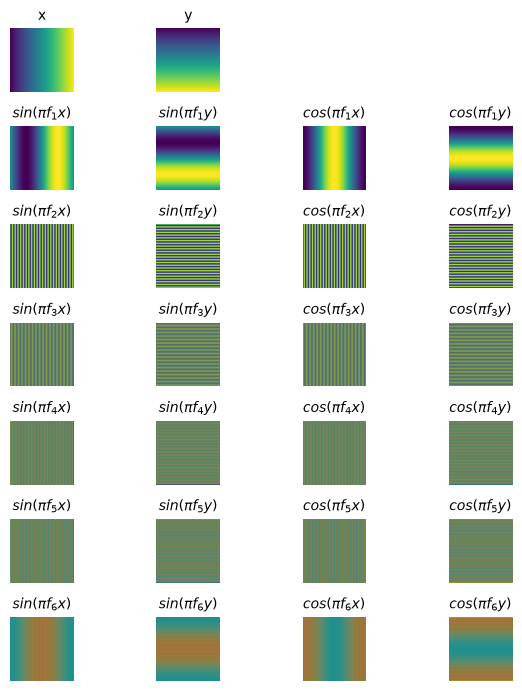

In [11]:
titles = ["x", "y"]
for f in range(1, 6 + 1):
    titles += [
        f"$sin(πf_{f}x)$",
        f"$sin(πf_{f}y)$",
        f"$cos(πf_{f}x)$",
        f"$cos(πf_{f}y)$",
    ]

plt.figure(figsize=(6, 8))
for dim in range(26):
    plt.subplot(8, 4, dim + 1 + (2 if dim > 1 else 0))
    plt.imshow(pos_encodings[..., dim])
    plt.title(titles[dim], fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

## BLIP2


In [2]:
model_id = "Salesforce/blip2-opt-2.7b"
blip2_processor = Blip2Processor.from_pretrained(model_id)
blip2_model = Blip2ForConditionalGeneration.from_pretrained(
    model_id, device_map="auto", dtype="auto"
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1247 [00:00<?, ?it/s]

/opt/anaconda3/envs/ml/lib/python3.12/site-packages/accelerate/utils/modeling.py:1627: UserWarning: The following device_map keys do not match any submodules in the model: ['query_tokens']
  warnings.warn(
Some parameters are on the meta device because they were offloaded to the disk.


In [3]:
image_url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(urllib.request.urlopen(image_url))
inputs = blip2_processor(images=image, return_tensors="pt")
inputs = inputs.to("mps", dtype=torch.float16)
with torch.no_grad():
    generated_ids = blip2_model.generate(**inputs)

generated_text = blip2_processor.batch_decode(generated_ids)

/opt/anaconda3/envs/ml/lib/python3.12/site-packages/transformers/generation/utils.py:1625: UserWarning: Using the model-agnostic default `max_length` (=53) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


In [4]:
generated_text = blip2_processor.batch_decode(generated_ids, skip_special_tokens=True)
generated_text

['two cats laying on a couch\n']

In [10]:
load_dotenv()
APY_KEY = os.getenv("API_KEY")

In [ ]:
gemini_client = genai.Client(api_key=APY_KEY)
cats_photo = gemini_client.files.upload(file="my_cats_photo.jpg")
question = " What kind of animal and how many? Format: [animal, number]"
response = gemini_client.models.generate_content(
    model="gemini-2.5-flash"
    contents=[cats_photo, question])
print(response.text)

[cat, 2]
